Gabriel Ido Arthur Nababan

231402115

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
(x_train_full, y_train_full), (x_test, y_test) = \
    keras.datasets.mnist.load_data()

print("Train:", x_train_full.shape)
print("Test :", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 28, 28)
Test : (10000, 28, 28)


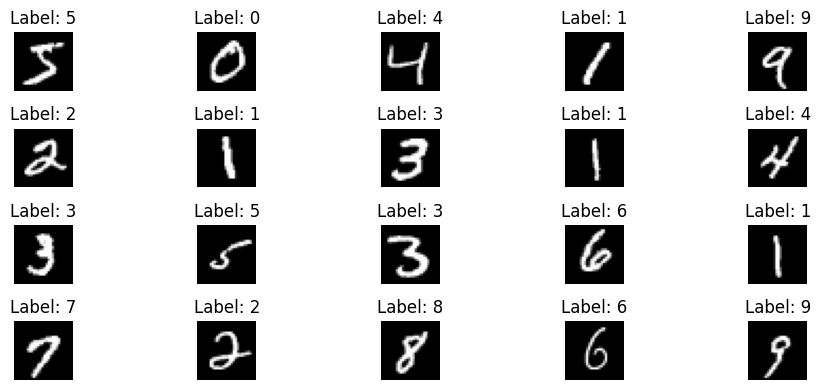

In [3]:
plt.figure(figsize=(10,4))

for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(f"Label: {y_train_full[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [5]:
x_train_full = np.expand_dims(x_train_full, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(x_train_full.shape)

(60000, 28, 28, 1)


In [6]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

print("Train:", x_train.shape)
print("Val  :", x_val.shape)
print("Test :", x_test.shape)

Train: (54000, 28, 28, 1)
Val  : (6000, 28, 28, 1)
Test : (10000, 28, 28, 1)


In [7]:
model = keras.Sequential([

    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(
        10,
        activation="softmax"
    )
])

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

ini yang di edit

optimizer dari adam ke sgd

In [9]:
model.compile(
    optimizer="sgd",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [10]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=3,
    batch_size=128
)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.6117 - loss: 1.2835 - val_accuracy: 0.8847 - val_loss: 0.4223
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.8932 - loss: 0.3559 - val_accuracy: 0.9083 - val_loss: 0.3097
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.9177 - loss: 0.2709 - val_accuracy: 0.9152 - val_loss: 0.2643


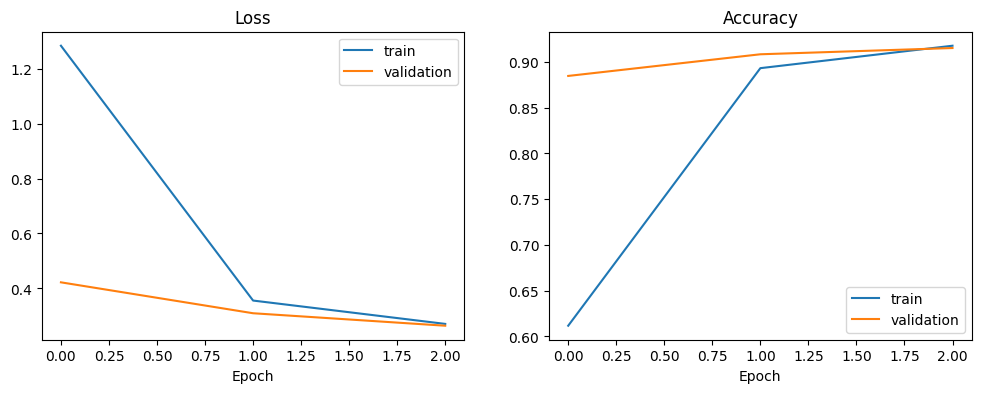

In [11]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [12]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test accuracy:", test_acc)
print("Test loss    :", test_loss)

Test accuracy: 0.9254999756813049
Test loss    : 0.24370604753494263


In [13]:
pred = model.predict(x_test[:10])
predicted_labels = np.argmax(pred, axis=1)

print("Predicted:", predicted_labels)
print("\n")
print("Actual   :", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Predicted: [7 2 1 0 4 1 4 9 6 9]


Actual   : [7 2 1 0 4 1 4 9 5 9]


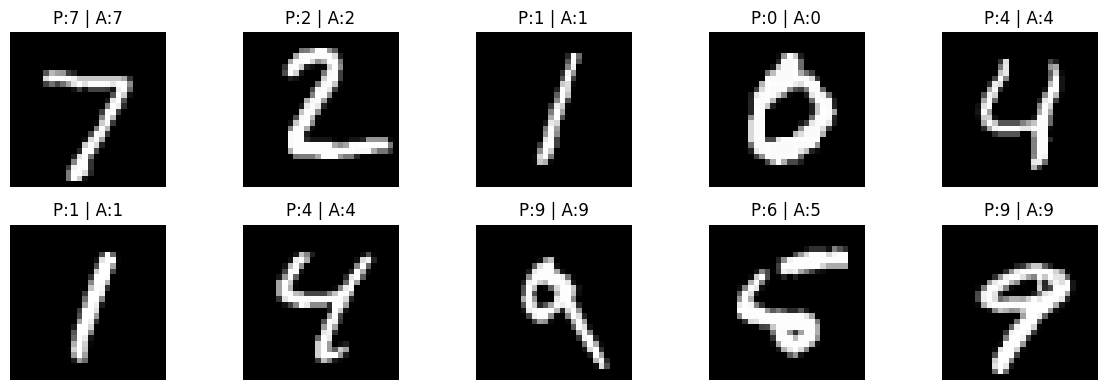

In [14]:
plt.figure(figsize=(12,4))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title(
        f"P:{predicted_labels[i]} | A:{y_test[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# Kesimpulan

Baseline: optimizer = "adam"

Modifikasi: optimizer = "sgd"

# Perbedaan
1. Kecepatan Konvergensi:
   - Adam: Menggunakan *adaptive learning rate* dan *momentum*, sehingga model langsung mencapai akurasi validasi 97.43% pada epoch 1 dan konvergen stabil di epoch 3 dengan akurasi uji 98.57%.
   - SGD: Pada epoch 1, akurasi training baru berada di 61.17% dan naik menjadi 91.77% pada epoch 3.
2. Akurasi Pengujian dan Kesalahan Prediksi:
   - Penurunan akurasi uji dari 98.57% menjadi 92.55% berdampak langsung pada hasil prediksi citra digit tulisan tangan. Terbukti pada visualisasi 10 sampel uji terakhir, model dengan SGD salah mengklasifikasikan sampel ke-9 (citra digit angka 5 salah diprediksi sebagai angka 6 / P:6 | A:5), sedangkan model dengan Adam mampu memprediksi seluruh 10 sampel dengan sempurna (100%).